#Maestría en Ciencias de los Datos y Analítica
#Aprendizaje Automatico

#Tabular Deep Learning - Ejercicio aplicado

##Elaborado por:
*   Esteban Salazar
*   Luis Alberto Ortiz


##Descripción:
### Aplicación del modelo de Deep Learning FT-Transformer (Feature Tokenizer + Transformer) para procesar y analizar datos tabulares (tablas con filas y columnas).
###FT-Transformer convierte cada columna o característica de una fila en un elemento individual para que la red neuronal entienda las relaciones entre ellas

###Esto se llama Tokenización de características o transformación en vectores numéricos uniformes llamados tokens

###Se trabaja con Embeddings para identificar relaciones entre datos de una caracterpistica que pudieran estar relacionados


In [20]:
import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
AZUL, GRIS = "#2F5BFF", "#9AA3B5"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 11})

# ═══════════════════════════════════════════════════════════
# PASO 1 · LOS DATOS: una tabla real (¿gana una persona más de 50K al año?)
# ═══════════════════════════════════════════════════════════
df = fetch_openml("adult", version=2, as_frame=True).frame.drop(columns=["fnlwgt"])
y = (df["class"] == ">50K").astype(int).values
X = df.drop(columns=["class"])
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()
for c in cat_cols:
    X[c] = X[c].astype(object).fillna("desconocido").astype(str)

print("PASO 1 · Así se ve una tabla de datos (filas = personas, columnas = características)")
display(df.head(6))
print(f"\n{len(X):,} filas · {len(cat_cols)} columnas categóricas · {len(num_cols)} numéricas")

# Separar en entrenamiento / validación / prueba
idx = np.arange(len(X))
tr, tmp = train_test_split(idx, test_size=0.3, random_state=0, stratify=y)
va, te = train_test_split(tmp, test_size=0.5, random_state=0, stratify=y[tmp])



PASO 1 · Así se ve una tabla de datos (filas = personas, columnas = características)


,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K
5,34,Private,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K



48,842 filas · 8 columnas categóricas · 5 numéricas


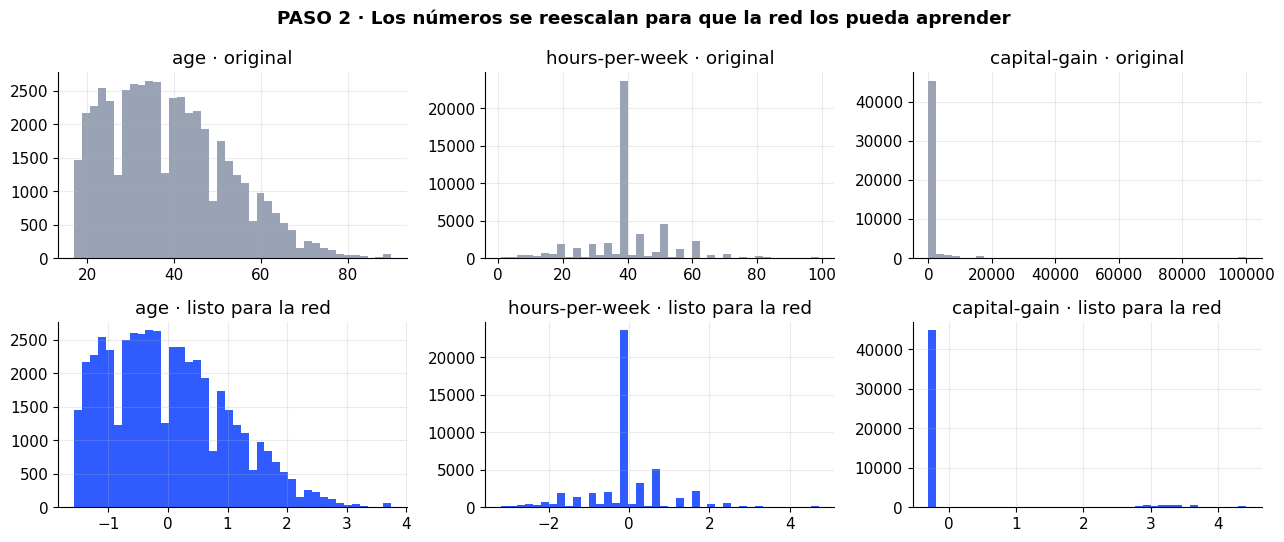

In [21]:
# ═══════════════════════════════════════════════════════════
# PASO 2 · PREPROCESAMIENTO: preparar los datos para la red
# ═══════════════════════════════════════════════════════════
# Categorías -> números enteros (luego la red los convierte en embeddings)
cat_maps, Xc = {}, np.zeros((len(X), len(cat_cols)), dtype=np.int64)
for j, c in enumerate(cat_cols):
    cats = sorted(X.iloc[tr][c].unique())
    cat_maps[c] = {v: i + 1 for i, v in enumerate(cats)}   # 0 = categoría desconocida
    Xc[:, j] = X[c].map(cat_maps[c]).fillna(0).astype(int).values

# Números -> escala común (log para valores muy sesgados + estandarización)
Xn_log = X[num_cols].copy().astype(float)
for c in ["capital-gain", "capital-loss"]:
    Xn_log[c] = np.log1p(Xn_log[c])
scaler = StandardScaler().fit(Xn_log.iloc[tr])
Xn = scaler.transform(Xn_log).astype(np.float32)

fig, axs = plt.subplots(2, 3, figsize=(13, 5.5))
for k, c in enumerate(["age", "hours-per-week", "capital-gain"]):
    j = num_cols.index(c)
    axs[0, k].hist(X[c], bins=40, color=GRIS); axs[0, k].set_title(f"{c} · original")
    axs[1, k].hist(Xn[:, j], bins=40, color=AZUL); axs[1, k].set_title(f"{c} · listo para la red")
fig.suptitle("PASO 2 · Los números se reescalan para que la red los pueda aprender", fontweight="bold")
plt.tight_layout(); plt.show()


In [22]:
# ═══════════════════════════════════════════════════════════
# PASO 3 · LA RED NEURONAL PROFUNDA
# ═══════════════════════════════════════════════════════════
class TabNN(nn.Module):
    def __init__(self, cat_sizes, n_num):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(n + 1, min(16, (n + 1) // 2 + 1)) for n in cat_sizes])
        d = sum(e.embedding_dim for e in self.embs) + n_num
        def bloque(i, o): return nn.Sequential(nn.Linear(i, o), nn.BatchNorm1d(o), nn.ReLU(), nn.Dropout(0.2))
        self.capa1, self.capa2, self.capa3 = bloque(d, 128), bloque(128, 64), bloque(64, 32)
        self.salida = nn.Linear(32, 1)

    def forward(self, xc, xn, ocultas=False):
        e = [emb(xc[:, i]) for i, emb in enumerate(self.embs)]
        entrada = torch.cat(e + [xn], dim=1)
        h1 = self.capa1(entrada); h2 = self.capa2(h1); h3 = self.capa3(h2)
        out = self.salida(h3).squeeze(1)
        return (out, [entrada, h1, h2, h3]) if ocultas else out

tt = lambda a, dt: torch.tensor(a, dtype=dt, device=device)
XC, XN, Y = tt(Xc, torch.long), tt(Xn, torch.float32), tt(y, torch.float32)
modelo = TabNN([len(cat_maps[c]) for c in cat_cols], len(num_cols)).to(device)
opt = torch.optim.Adam(modelo.parameters(), lr=2e-3, weight_decay=1e-5)
loss_fn = nn.BCEWithLogitsLoss()

def evaluar(ix):
    modelo.eval()
    with torch.no_grad():
        ix = torch.tensor(ix, device=device)
        out = modelo(XC[ix], XN[ix])
        return loss_fn(out, Y[ix]).item(), ((out > 0).float() == Y[ix]).float().mean().item()



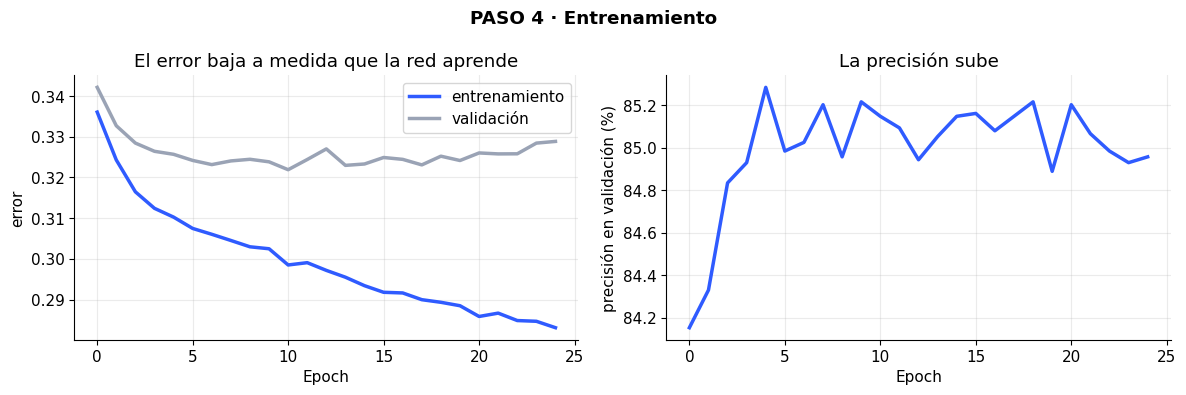

In [23]:
# ═══════════════════════════════════════════════════════════
# PASO 4 · ENTRENAMIENTO: la red mejora en cada Epoch
# ═══════════════════════════════════════════════════════════
hist = {"train": [], "val": [], "acc": []}
t0 = time.time()
for ep in range(25):
    modelo.train()
    perm = np.random.permutation(tr)
    for i in range(0, len(perm), 512):
        b = torch.tensor(perm[i:i + 512], device=device)
        opt.zero_grad(); loss_fn(modelo(XC[b], XN[b]), Y[b]).backward(); opt.step()
    hist["train"].append(evaluar(tr)[0])
    l, a = evaluar(va); hist["val"].append(l); hist["acc"].append(a)
t_red = time.time() - t0
acc_red = evaluar(te)[1]

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(hist["train"], color=AZUL, lw=2.5, label="entrenamiento")
axs[0].plot(hist["val"], color=GRIS, lw=2.5, label="validación")
axs[0].set(title="El error baja a medida que la red aprende", xlabel="Epoch", ylabel="error"); axs[0].legend()
axs[1].plot(np.array(hist["acc"]) * 100, color=AZUL, lw=2.5)
axs[1].set(title="La precisión sube", xlabel="Epoch", ylabel="precisión en validación (%)")
fig.suptitle("PASO 4 · Entrenamiento", fontweight="bold"); plt.tight_layout(); plt.show()



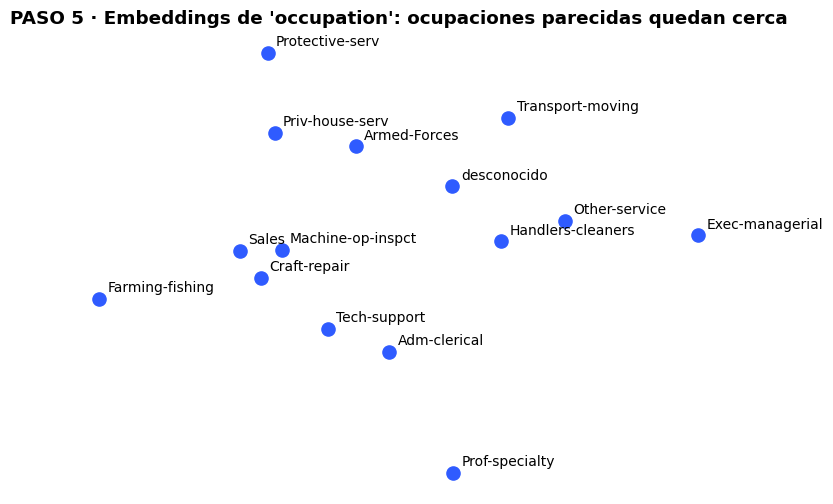

In [24]:
# ═══════════════════════════════════════════════════════════
# PASO 5 · EMBEDDINGS: cómo la red "entiende" las categorías
# ═══════════════════════════════════════════════════════════
col = "occupation"; j = cat_cols.index(col)
W = modelo.embs[j].weight.detach().cpu().numpy()[1:]
nombres = sorted(cat_maps[col], key=lambda k: cat_maps[col][k])
P = PCA(2).fit_transform(W)
plt.figure(figsize=(8.5, 6))
plt.scatter(P[:, 0], P[:, 1], s=90, color=AZUL)
for (x_, y_), n in zip(P, nombres):
    plt.annotate(n, (x_, y_), xytext=(6, 5), textcoords="offset points", fontsize=10)
plt.title("PASO 5 · Embeddings de 'occupation': ocupaciones parecidas quedan cerca", fontweight="bold")
plt.axis("off"); plt.show()


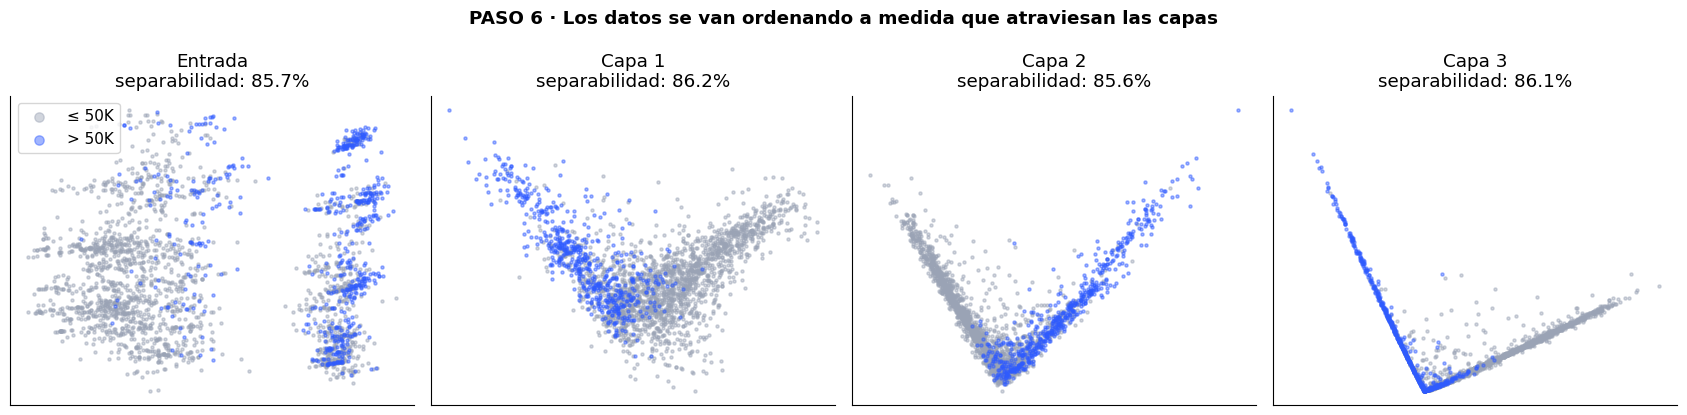

In [25]:
# ═══════════════════════════════════════════════════════════
# PASO 6 · ¿QUÉ PASA POR DENTRO? Los datos capa por capa
# ═══════════════════════════════════════════════════════════
def ocultas(ix):
    modelo.eval()
    with torch.no_grad():
        ix = torch.tensor(ix, device=device)
        _, hs = modelo(XC[ix], XN[ix], ocultas=True)
    return [h.cpu().numpy() for h in hs]

ix_tr, ix_te = tr[:8000], te[:2500]
H_tr, H_te = ocultas(ix_tr), ocultas(ix_te)
nombres_capas = ["Entrada", "Capa 1", "Capa 2", "Capa 3"]
fig, axs = plt.subplots(1, 4, figsize=(17, 4.2))
for k, ax in enumerate(axs):
    sep = LogisticRegression(max_iter=500).fit(H_tr[k], y[ix_tr]).score(H_te[k], y[ix_te]) * 100
    Z = PCA(2).fit_transform(H_te[k])
    for clase, color, lab in [(0, GRIS, "≤ 50K"), (1, AZUL, "> 50K")]:
        m = y[ix_te] == clase
        ax.scatter(Z[m, 0], Z[m, 1], s=5, alpha=.45, color=color, label=lab)
    ax.set_title(f"{nombres_capas[k]}\nseparabilidad: {sep:.1f}%"); ax.set_xticks([]); ax.set_yticks([])
axs[0].legend(markerscale=3)
fig.suptitle("PASO 6 · Los datos se van ordenando a medida que atraviesan las capas", fontweight="bold")
plt.tight_layout(); plt.show()


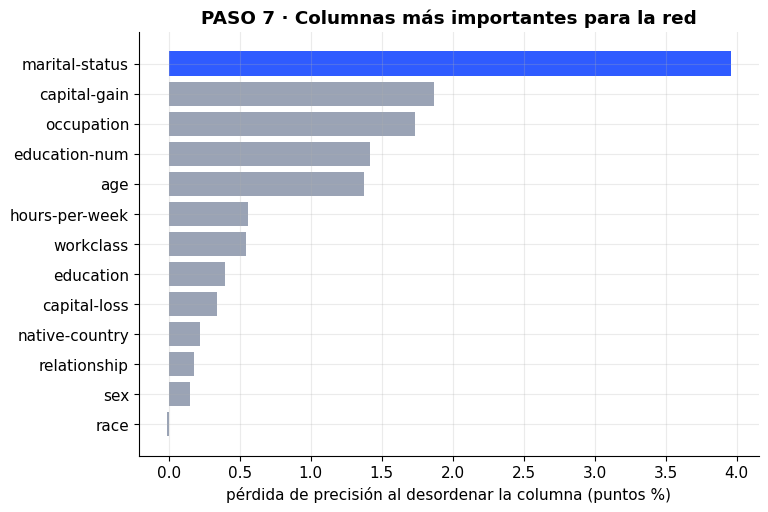

In [26]:
# ═══════════════════════════════════════════════════════════
# PASO 7 · ¿QUÉ COLUMNAS MIRA LA RED?  (se desordena una columna y se mide cuánto empeora)
# ═══════════════════════════════════════════════════════════
modelo.eval(); base = acc_red; imp = {}
ix = torch.tensor(te, device=device)
for k, c in enumerate(cat_cols + num_cols):
    xc, xn = XC[ix].clone(), XN[ix].clone()
    p = torch.randperm(len(ix), device=device)
    if k < len(cat_cols): xc[:, k] = xc[p, k]
    else: xn[:, k - len(cat_cols)] = xn[p, k - len(cat_cols)]
    with torch.no_grad():
        imp[c] = base - ((modelo(xc, xn) > 0).float() == Y[ix]).float().mean().item()
s = pd.Series(imp).sort_values()
plt.figure(figsize=(8, 5.5))
plt.barh(s.index, s.values * 100, color=[AZUL if v > 0.02 else GRIS for v in s.values])
plt.title("PASO 7 · Columnas más importantes para la red", fontweight="bold")
plt.xlabel("pérdida de precisión al desordenar la columna (puntos %)"); plt.show()


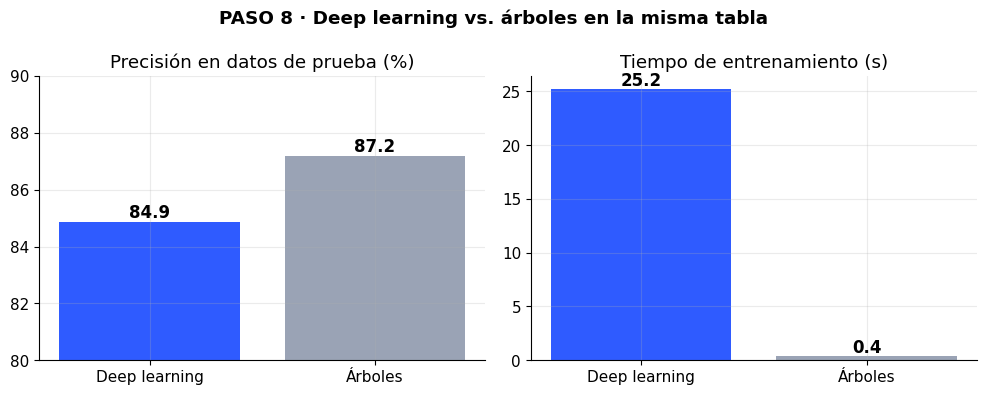

Deep learning: 84.86% en 25.2s  |  Árboles: 87.20% en 0.4s


In [27]:
# ═══════════════════════════════════════════════════════════
# PASO 8 · DUELO FINAL: deep learning vs. árboles potenciados
# ═══════════════════════════════════════════════════════════
Xt = np.hstack([Xc, Xn]); mask = [True] * len(cat_cols) + [False] * len(num_cols)
t0 = time.time()
arbol = HistGradientBoostingClassifier(categorical_features=mask, random_state=0).fit(Xt[tr], y[tr])
t_arbol = time.time() - t0
acc_arbol = arbol.score(Xt[te], y[te])

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].bar(["Deep learning", "Árboles"], [acc_red * 100, acc_arbol * 100], color=[AZUL, GRIS])
axs[0].set(title="Precisión en datos de prueba (%)", ylim=(80, 90))
axs[1].bar(["Deep learning", "Árboles"], [t_red, t_arbol], color=[AZUL, GRIS])
axs[1].set(title="Tiempo de entrenamiento (s)")
for ax in axs:
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=12, fontweight="bold")
fig.suptitle("PASO 8 · Deep learning vs. árboles en la misma tabla", fontweight="bold")
plt.tight_layout(); plt.show()
print(f"Deep learning: {acc_red*100:.2f}% en {t_red:.1f}s  |  Árboles: {acc_arbol*100:.2f}% en {t_arbol:.1f}s")

In [28]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch, torch.nn as nn
import ipywidgets as w
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
AZUL, NARANJA = "#2F5BFF", "#F2994A"
CMAP = LinearSegmentedColormap.from_list("sube_baja", [NARANJA, "#F5F7FA", AZUL])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

ES = {"age": "edad", "workclass": "tipo de empleo", "education": "educación",
      "education-num": "años de estudio", "marital-status": "estado civil",
      "occupation": "ocupación", "relationship": "relación", "race": "raza", "sex": "sexo",
      "capital-gain": "ganancia capital", "capital-loss": "pérdida capital",
      "hours-per-week": "horas/semana", "native-country": "país origen"}

# ═══════════════════════════════════════════════════════════
# 1 · LOS DATOS: una tabla real. ¿La persona gana más de 50K al año?
# ═══════════════════════════════════════════════════════════
df = fetch_openml("adult", version=2, as_frame=True).frame.drop(columns=["fnlwgt"])
y = (df["class"] == ">50K").astype(int).values
X = df.drop(columns=["class"]).copy()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()
for c in cat_cols:
    X[c] = X[c].astype(object).fillna("desconocido").astype(str)
cols = cat_cols + num_cols
ETIQ = [ES.get(c, c) for c in cols]

print("Así se ve la tabla: cada fila es una persona")
display(df.head(6))

idx = np.arange(len(X))
tr, tmp = train_test_split(idx, test_size=0.3, random_state=0, stratify=y)
va, te = train_test_split(tmp, test_size=0.5, random_state=0, stratify=y[tmp])



Así se ve la tabla: cada fila es una persona


,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K
5,34,Private,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K


In [29]:
# ═══════════════════════════════════════════════════════════
# 2 · PREPARAR LOS DATOS (categorías -> índices, números -> misma escala)
# ═══════════════════════════════════════════════════════════
cat_maps = {c: {v: i + 1 for i, v in enumerate(sorted(X.iloc[tr][c].unique()))} for c in cat_cols}

def log_num(d):
    n = d[num_cols].astype(float).copy()
    for c in ["capital-gain", "capital-loss"]:
        n[c] = np.log1p(n[c])
    return n

scaler = StandardScaler().fit(log_num(X.iloc[tr]))

def a_tensores(d):
    xc = np.stack([d[c].astype(str).map(cat_maps[c]).fillna(0).astype(int).values for c in cat_cols], 1)
    xn = scaler.transform(log_num(d)).astype(np.float32)
    return torch.tensor(xc, dtype=torch.long, device=device), torch.tensor(xn, device=device)

XC, XN = a_tensores(X)
Y = torch.tensor(y, dtype=torch.float32, device=device)

# ═══════════════════════════════════════════════════════════
# 3 · MODELO: un mini FT-Transformer (cada columna se vuelve un "token")
# ═══════════════════════════════════════════════════════════
class Bloque(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.att = nn.MultiheadAttention(d, h, dropout=0.1, batch_first=True)
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(0.1), nn.Linear(2 * d, d))
    def forward(self, x):
        a, wts = self.att(x, x, x, need_weights=True)
        x = self.n1(x + a)
        return self.n2(x + self.ff(x)), wts

class FTLite(nn.Module):
    def __init__(self, cat_sizes, n_num, d=32, h=4, capas=2):
        super().__init__()
        self.emb_cat = nn.ModuleList([nn.Embedding(n + 1, d) for n in cat_sizes])
        self.w_num = nn.Parameter(torch.randn(n_num, d) * 0.1)
        self.b_num = nn.Parameter(torch.zeros(n_num, d))
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.1)
        self.bloques = nn.ModuleList([Bloque(d, h) for _ in range(capas)])
        self.norm, self.salida = nn.LayerNorm(d), nn.Linear(d, 1)
    def forward(self, xc, xn, atenciones=False):
        tc = torch.stack([e(xc[:, i]) for i, e in enumerate(self.emb_cat)], 1)
        tn = xn.unsqueeze(-1) * self.w_num + self.b_num
        x = torch.cat([self.cls.expand(len(xc), -1, -1), tc, tn], 1)
        ws = []
        for b in self.bloques:
            x, wts = b(x); ws.append(wts)
        out = self.salida(self.norm(x[:, 0])).squeeze(1)
        return (out, ws) if atenciones else out

modelo = FTLite([len(cat_maps[c]) for c in cat_cols], len(num_cols)).to(device)
opt = torch.optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)
loss_fn = nn.BCEWithLogitsLoss()

def precision(ix):
    ix = torch.tensor(ix, device=device); modelo.eval()
    with torch.no_grad():
        return ((modelo(XC[ix], XN[ix]) > 0).float() == Y[ix]).float().mean().item()

print("\nEntrenando la red...")
for ep in range(15):
    modelo.train(); perm = np.random.permutation(tr)
    for i in range(0, len(perm), 512):
        b = torch.tensor(perm[i:i + 512], device=device)
        opt.zero_grad(); loss_fn(modelo(XC[b], XN[b]), Y[b]).backward(); opt.step()
    #if ep % 3 == 2 or ep == 14:
    print(f"  Epoch {ep + 1:2d} · precisión en validación: {precision(va) * 100:.1f}%")
print(f"Precisión final en datos de prueba: {precision(te) * 100:.1f}%")



Entrenando la red...
  Epoch  1 · precisión en validación: 82.8%
  Epoch  2 · precisión en validación: 84.7%
  Epoch  3 · precisión en validación: 84.9%
  Epoch  4 · precisión en validación: 84.9%
  Epoch  5 · precisión en validación: 85.1%
  Epoch  6 · precisión en validación: 85.2%
  Epoch  7 · precisión en validación: 85.1%
  Epoch  8 · precisión en validación: 85.1%
  Epoch  9 · precisión en validación: 85.3%
  Epoch 10 · precisión en validación: 85.0%
  Epoch 11 · precisión en validación: 85.5%
  Epoch 12 · precisión en validación: 85.3%
  Epoch 13 · precisión en validación: 85.6%
  Epoch 14 · precisión en validación: 85.1%
  Epoch 15 · precisión en validación: 85.4%
Precisión final en datos de prueba: 85.7%


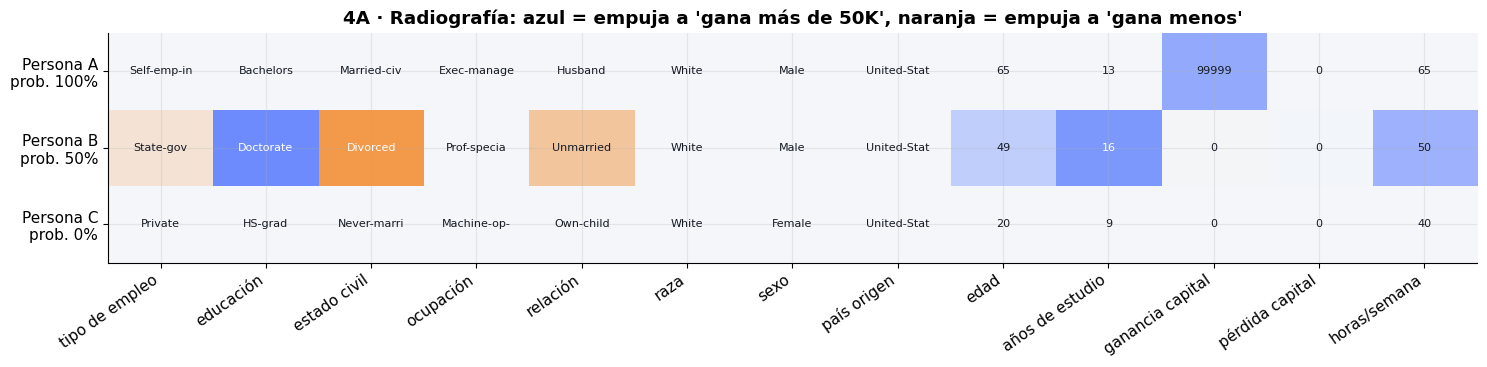

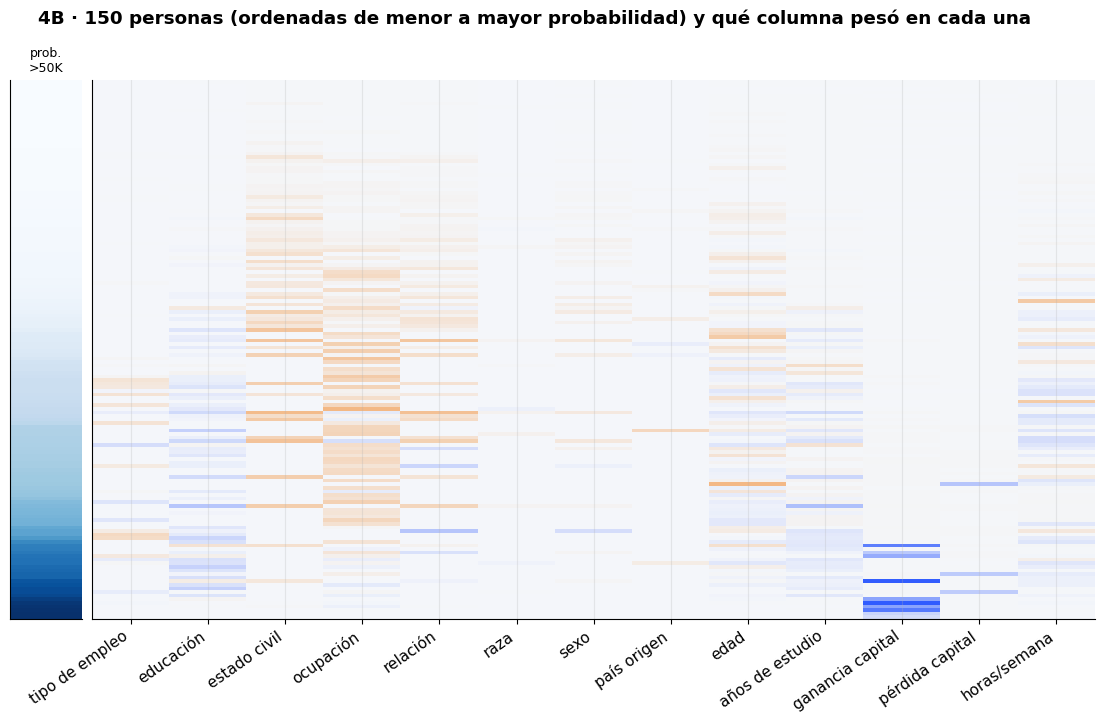

In [30]:
# ═══════════════════════════════════════════════════════════
# 4 · "TAPAR UNA CELDA": cuánto cambia la decisión si una columna se vuelve "típica"
# ═══════════════════════════════════════════════════════════
tipico_c = torch.mode(XC[torch.tensor(tr, device=device)], dim=0).values  # categoría más común

def atribuir(ix):
    modelo.eval()
    with torch.no_grad():
        xc, xn = XC[ix], XN[ix]
        p0 = torch.sigmoid(modelo(xc, xn)); A = []
        for k in range(len(cols)):
            c2, n2 = xc.clone(), xn.clone()
            if k < len(cat_cols): c2[:, k] = tipico_c[k]
            else: n2[:, k - len(cat_cols)] = 0          # 0 = valor promedio
            A.append(p0 - torch.sigmoid(modelo(c2, n2)))
    return p0.cpu().numpy(), torch.stack(A, 1).cpu().numpy()

# ─── 4A · Radiografía de 3 personas ───
with torch.no_grad():
    P_te = torch.sigmoid(modelo(XC[torch.tensor(te, device=device)], XN[torch.tensor(te, device=device)])).cpu().numpy()
elegidos = [int(te[np.argsort(P_te)[-5]]), int(te[np.argmin(abs(P_te - 0.5))]), int(te[np.argsort(P_te)[5]])]
nombres = ["Persona A", "Persona B", "Persona C"]
p, A = atribuir(torch.tensor(elegidos, device=device))
v = np.abs(A).max()
fig, ax = plt.subplots(figsize=(15, 3.8))
ax.imshow(A, cmap=CMAP, vmin=-v, vmax=v, aspect="auto")
ax.set_xticks(range(len(cols))); ax.set_xticklabels(ETIQ, rotation=35, ha="right")
ax.set_yticks(range(3)); ax.set_yticklabels([f"{n}\nprob. {pp * 100:.0f}%" for n, pp in zip(nombres, p)])
for i in range(3):
    for j in range(len(cols)):
        ax.text(j, i, str(X.iloc[elegidos[i]][cols[j]])[:11], ha="center", va="center", fontsize=8,
                color="white" if abs(A[i, j]) > 0.6 * v else "#151A24")
ax.set_title("4A · Radiografía: azul = empuja a 'gana más de 50K', naranja = empuja a 'gana menos'", fontweight="bold")
plt.tight_layout(); plt.show()

# ─── 4B · Mapa de calor de 150 personas (la tabla convertida en imagen) ───
rng = np.random.default_rng(1)
muestra = rng.choice(te, 150, replace=False)
p, A = atribuir(torch.tensor(muestra, device=device))
o = np.argsort(p); p, A = p[o], A[o]; v = np.abs(A).max()
fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [1, 14], "wspace": 0.02})
a0.imshow(p[:, None], cmap="Blues", vmin=0, vmax=1, aspect="auto"); a0.set_xticks([]); a0.set_yticks([])
a0.set_title("prob.\n>50K", fontsize=9)
a1.imshow(A, cmap=CMAP, vmin=-v, vmax=v, aspect="auto"); a1.set_yticks([])
a1.set_xticks(range(len(cols))); a1.set_xticklabels(ETIQ, rotation=35, ha="right")
fig.suptitle("4B · 150 personas (ordenadas de menor a mayor probabilidad) y qué columna pesó en cada una",
             fontweight="bold")
plt.show()


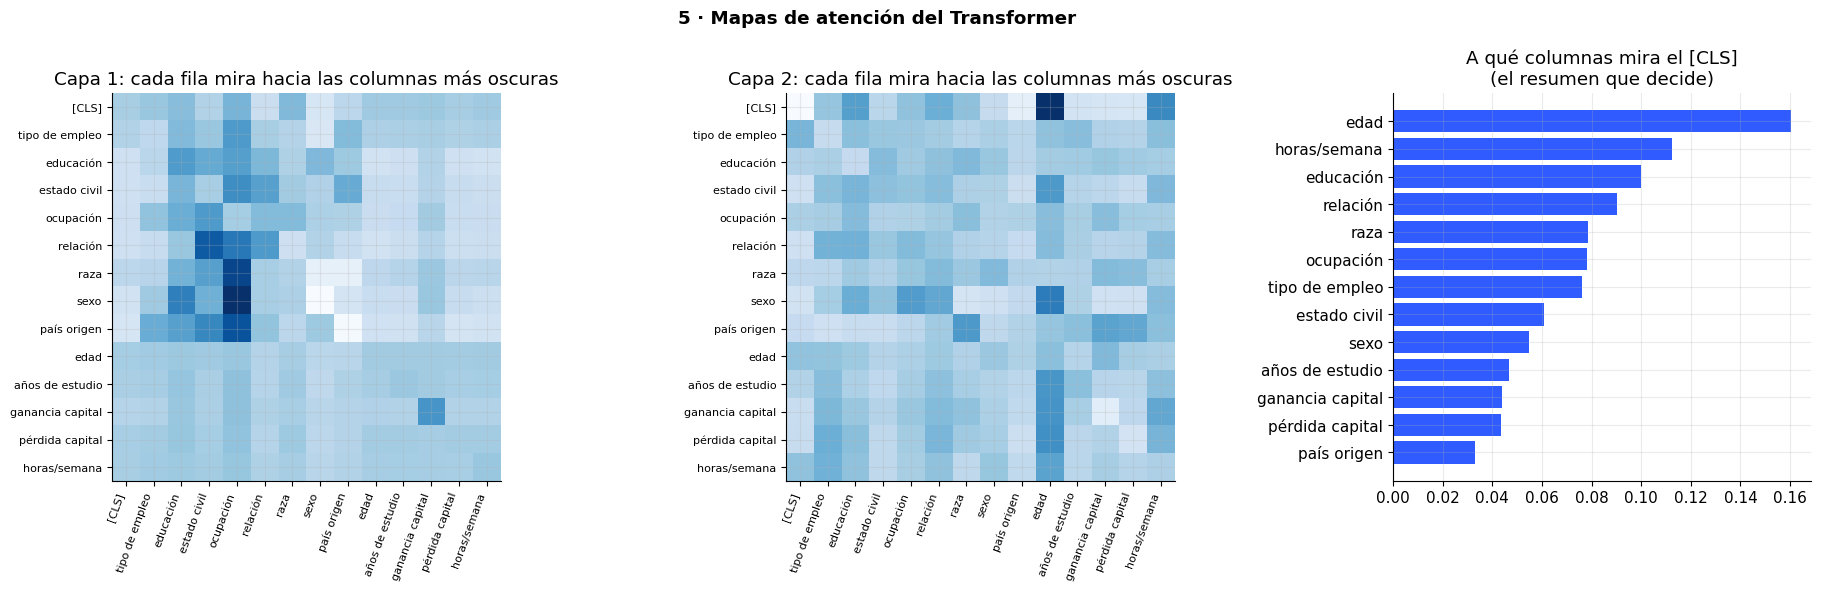

In [31]:
# ═══════════════════════════════════════════════════════════
# 5 · MAPAS DE ATENCIÓN: cómo se "hablan" las columnas entre sí
# ═══════════════════════════════════════════════════════════
tokens = ["[CLS]"] + ETIQ
ix = torch.tensor(te[:2000], device=device); modelo.eval()
with torch.no_grad():
    _, ws = modelo(XC[ix], XN[ix], atenciones=True)
M = [m.mean(0).cpu().numpy() for m in ws]
fig, axs = plt.subplots(1, 3, figsize=(19, 6), gridspec_kw={"width_ratios": [1, 1, 0.8]})
for k in range(2):
    axs[k].imshow(M[k], cmap="Blues")
    axs[k].set_xticks(range(len(tokens))); axs[k].set_xticklabels(tokens, rotation=70, ha="right", fontsize=8)
    axs[k].set_yticks(range(len(tokens))); axs[k].set_yticklabels(tokens, fontsize=8)
    axs[k].set_title(f"Capa {k + 1}: cada fila mira hacia las columnas más oscuras")
cls = M[-1][0, 1:]; orden = np.argsort(cls)
axs[2].barh(np.array(ETIQ)[orden], cls[orden], color=AZUL)
axs[2].set_title("A qué columnas mira el [CLS]\n(el resumen que decide)")
fig.suptitle("5 · Mapas de atención del Transformer", fontweight="bold")
plt.tight_layout(); plt.show()


In [32]:
# ═══════════════════════════════════════════════════════════
# 6 · INTERACTIVO: cambia los datos de una persona y mira la predicción
# ═══════════════════════════════════════════════════════════
base = {c: X[c].mode()[0] for c in cat_cols}; base.update({c: X[c].median() for c in num_cols})

def prob(**cambios):
    fila = dict(base); fila.update(cambios)
    xc, xn = a_tensores(pd.DataFrame([fila])); modelo.eval()
    with torch.no_grad():
        return torch.sigmoid(modelo(xc, xn)).item()

def mostrar(edad, estudio, horas, ganancia, estado, ocupacion):
    pr = prob(**{"age": edad, "education-num": estudio, "hours-per-week": horas,
                 "capital-gain": ganancia, "marital-status": estado, "occupation": ocupacion})
    fig, ax = plt.subplots(figsize=(9, 1.3))
    ax.barh([0], [100], color="#E3E9FF"); ax.barh([0], [pr * 100], color=AZUL)
    ax.set_xlim(0, 100); ax.set_yticks([])
    ax.set_title(f"Probabilidad de ganar más de 50K: {pr * 100:.0f}%", fontweight="bold")
    plt.show()

ctrl = {
    "edad": w.IntSlider(value=38, min=17, max=90, description="edad"),
    "estudio": w.IntSlider(value=10, min=1, max=16, description="estudios"),
    "horas": w.IntSlider(value=40, min=1, max=99, description="horas/sem"),
    "ganancia": w.IntSlider(value=0, min=0, max=20000, step=500, description="ganancia"),
    "estado": w.Dropdown(options=sorted(X["marital-status"].unique()), value=base["marital-status"], description="estado civil"),
    "ocupacion": w.Dropdown(options=sorted(X["occupation"].unique()), value=base["occupation"], description="ocupación"),
}
print("\n6 · Mueve los controles y mira cómo cambia la decisión de la red:")
display(w.VBox(list(ctrl.values())), w.interactive_output(mostrar, ctrl))


6 · Mueve los controles y mira cómo cambia la decisión de la red:


Output()